# Image Classification Robustness: Final Results

This notebook presents the final results used in the research report. It reuses the completed outer-fold results and focuses on clean performance, robustness under Gaussian blur and brightness reduction, input-condition sensitivity, and class-level confusion.


## 1. Load the completed experiment results

The three models use the same four feature representations, ten outer folds and seven image conditions.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display, Markdown

plt.style.use("seaborn-v0_8-whitegrid")

RESULTS_DIR = Path("results")
OUTPUT_DIR = RESULTS_DIR / "combined_analysis_improved"
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

MODEL_FILES = {
    "Logistic Regression": RESULTS_DIR / "logistic_regression" / "logistic_regression_results.csv",
    "MLP": RESULTS_DIR / "mlp" / "mlp_results.csv",
    "LightGBM": RESULTS_DIR / "lightgbm" / "lightgbm_results.csv",
}
MODEL_ORDER = ["Logistic Regression", "MLP", "LightGBM"]
FEATURE_ORDER = ["colour", "hog", "lbp", "spatial"]
CONDITION_ORDER = [
    "clean", "blur_mild", "blur_medium", "blur_severe",
    "brightness_mild", "brightness_medium", "brightness_severe",
]
METRICS = ["accuracy", "macro_precision", "macro_recall", "macro_f1"]
MODEL_COLORS = {
    "Logistic Regression": "#1f77b4",
    "MLP": "#ff7f0e",
    "LightGBM": "#2ca02c",
}

frames = []
for model_name, path in MODEL_FILES.items():
    frame = pd.read_csv(path)
    frame["model"] = model_name
    frames.append(frame)
results_df = pd.concat(frames, ignore_index=True)
results_df["condition"] = pd.Categorical(
    results_df["condition"], categories=CONDITION_ORDER, ordered=True
)

key_columns = ["model", "feature_representation", "outer_fold", "condition"]
assert not results_df.duplicated(key_columns).any()
assert not results_df[METRICS].isna().any().any()
print(f"Loaded {len(results_df)} result rows from {len(MODEL_ORDER)} models.")


Loaded 840 result rows from 3 models.


## 2. Prepare fold-level summaries

Each model receives an equal-weight average over the four feature representations inside every outer fold. Mean and SD are then calculated from the ten outer-fold values. Robustness losses always compare a degraded result with the clean result from the same model, feature representation and fold.


In [2]:
feature_fold_metrics = (
    results_df
    .groupby(
        ["model", "feature_representation", "outer_fold", "condition"],
        observed=True,
    )[METRICS]
    .mean()
    .reset_index()
)
model_fold_metrics = (
    feature_fold_metrics
    .groupby(["model", "outer_fold", "condition"], observed=True)[METRICS]
    .mean()
    .reset_index()
)
summary_df = (
    model_fold_metrics
    .groupby(["model", "condition"], observed=True)[METRICS]
    .agg(["mean", "std"])
    .reset_index()
)
summary_df.columns = [
    "_".join(column).strip("_") if isinstance(column, tuple) else column
    for column in summary_df.columns
]
summary_df.columns = [column.replace("_std", "_sd") for column in summary_df.columns]
clean_baseline_df = summary_df[summary_df["condition"] == "clean"].copy()

clean_f1 = (
    feature_fold_metrics[feature_fold_metrics["condition"] == "clean"]
    [["model", "feature_representation", "outer_fold", "macro_f1"]]
    .rename(columns={"macro_f1": "clean_macro_f1"})
)
paired_df = (
    feature_fold_metrics[feature_fold_metrics["condition"] != "clean"]
    .merge(
        clean_f1,
        on=["model", "feature_representation", "outer_fold"],
        validate="many_to_one",
    )
)
paired_df["corruption"] = paired_df["condition"].astype(str).str.split("_").str[0]
paired_df["severity_order"] = paired_df["condition"].astype(str).map({
    "blur_mild": 1, "blur_medium": 2, "blur_severe": 3,
    "brightness_mild": 1, "brightness_medium": 2, "brightness_severe": 3,
})
paired_df["macro_f1_drop"] = paired_df["clean_macro_f1"] - paired_df["macro_f1"]

model_fold_change_df = (
    paired_df
    .groupby(
        ["model", "outer_fold", "corruption", "condition", "severity_order"],
        observed=True,
    )["macro_f1_drop"]
    .mean()
    .reset_index()
)
change_summary_df = (
    model_fold_change_df
    .groupby(
        ["model", "corruption", "condition", "severity_order"],
        observed=True,
    )["macro_f1_drop"]
    .agg(["mean", "std"])
    .reset_index()
    .rename(columns={"std": "sd"})
)


## 3. Clean-image baseline

Table 1 reports Mean ± SD across the ten outer folds. Each fold gives equal weight to Colour, HOG, LBP and Spatial features.


In [3]:
table_rows = []
table_metrics = {
    "Accuracy": "accuracy",
    "Precision": "macro_precision",
    "Recall": "macro_recall",
    "F1": "macro_f1",
}
for model_name in MODEL_ORDER:
    row = clean_baseline_df[clean_baseline_df["model"] == model_name].iloc[0]
    values = {"Model": model_name}
    for heading, metric in table_metrics.items():
        values[heading] = f"{row[metric + '_mean']:.4f} ± {row[metric + '_sd']:.4f}"
    table_rows.append(values)

table_1_df = pd.DataFrame(table_rows).set_index("Model")
display(table_1_df)


,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.6488 ± 0.0094,0.6461 ± 0.0092,0.6494 ± 0.0093,0.6446 ± 0.0091
MLP,0.6813 ± 0.0083,0.6828 ± 0.0088,0.6829 ± 0.0081,0.6821 ± 0.0085
LightGBM,0.7077 ± 0.0094,0.7094 ± 0.0092,0.7086 ± 0.0093,0.7082 ± 0.0092


## 4. Overall robustness across models

The solid part of each bar is the degraded Macro-F1 and the hatched part is the paired loss from Clean. Their total equals the clean Macro-F1 for that model. Error bars show Mean ± SD across ten outer folds.


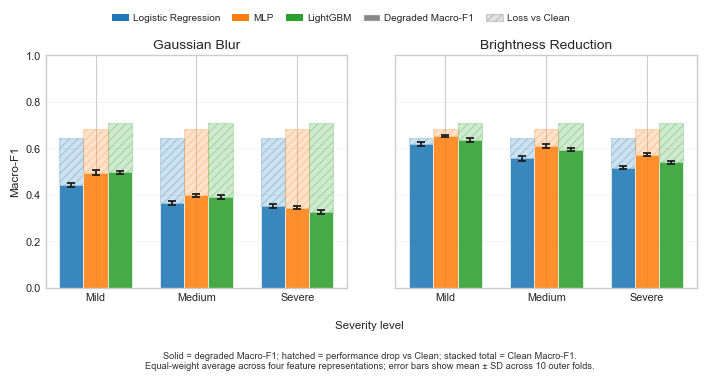

In [4]:
compact_conditions = {
    "blur": (["blur_mild", "blur_medium", "blur_severe"], "Gaussian Blur"),
    "brightness": (
        ["brightness_mild", "brightness_medium", "brightness_severe"],
        "Brightness Reduction",
    ),
}

def macro_f1_values(model_name, condition_name, corruption_name):
    actual = summary_df[
        (summary_df["model"] == model_name) &
        (summary_df["condition"] == condition_name)
    ].iloc[0]
    change = change_summary_df[
        (change_summary_df["model"] == model_name) &
        (change_summary_df["condition"] == condition_name) &
        (change_summary_df["corruption"] == corruption_name)
    ].iloc[0]
    return (
        float(actual["macro_f1_mean"]),
        float(actual["macro_f1_sd"]),
        float(change["mean"]),
    )

bar_width = 0.24
positions = np.arange(3)
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.75), sharey=True)

for axis, (corruption_name, (conditions, title)) in zip(
    axes, compact_conditions.items()
):
    for model_index, model_name in enumerate(MODEL_ORDER):
        x_values = positions + (model_index - 1) * bar_width
        values = [
            macro_f1_values(model_name, condition, corruption_name)
            for condition in conditions
        ]
        actual = np.array([value[0] for value in values])
        actual_sd = np.array([value[1] for value in values])
        loss = np.array([value[2] for value in values])
        colour = MODEL_COLORS[model_name]

        axis.bar(
            x_values, actual, width=bar_width, color=colour,
            alpha=0.88, edgecolor="white", linewidth=0.5, zorder=2,
        )
        axis.bar(
            x_values, loss, width=bar_width, bottom=actual,
            color=colour, alpha=0.22, edgecolor=colour,
            linewidth=0.8, hatch="////", zorder=2,
        )
        axis.errorbar(
            x_values, actual, yerr=actual_sd, fmt="none",
            ecolor="#1f1f1f", elinewidth=1.3,
            capsize=3.2, capthick=1.3, zorder=4,
        )

    axis.set_xticks(positions, ["Mild", "Medium", "Severe"])
    axis.set_title(title, fontsize=10, pad=5)
    axis.set_ylim(0, 1)
    axis.tick_params(axis="both", labelsize=7.8)
    axis.grid(axis="y", alpha=0.22, linewidth=0.6)
    axis.set_axisbelow(True)

axes[0].set_ylabel("Macro-F1", fontsize=8.5)
model_handles = [
    Patch(facecolor=MODEL_COLORS[name], edgecolor="none", label=name)
    for name in MODEL_ORDER
]
meaning_handles = [
    Patch(facecolor="#777777", alpha=0.88, edgecolor="white", label="Degraded Macro-F1"),
    Patch(facecolor="#777777", alpha=0.22, edgecolor="#555555",
          hatch="////", label="Loss vs Clean"),
]
fig.legend(
    handles=model_handles + meaning_handles, loc="upper center",
    bbox_to_anchor=(0.5, 0.995), ncol=5, frameon=False, fontsize=7.2,
    columnspacing=1.15, handlelength=1.7, handletextpad=0.45,
)
fig.supxlabel("Severity level", x=0.54, y=0.125, fontsize=8.3)
fig.text(
    0.54, 0.018,
    "Solid = degraded Macro-F1; hatched = performance drop vs Clean; "
    "stacked total = Clean Macro-F1.\n"
    "Equal-weight average across four feature representations; "
    "error bars show mean ± SD across 10 outer folds.",
    ha="center", va="bottom", fontsize=6.7, color="#333333",
)
fig.subplots_adjust(left=0.09, right=0.995, bottom=0.24, top=0.86, wspace=0.16)
fig.savefig(FIGURE_DIR / "06_combined_macro_f1_robustness.png", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "06_combined_macro_f1_robustness.pdf", bbox_inches="tight")
display(fig)
plt.close(fig)


## 5. Sensitivity of the four input conditions

This figure compares degradation trends rather than clean performance. The three models are averaged equally inside each fold, followed by Mean ± SD across the ten folds.


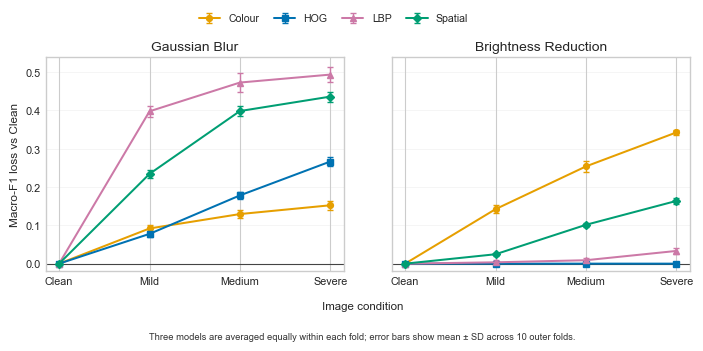

In [5]:
input_fold_drop_df = (
    paired_df
    .groupby(
        ["feature_representation", "outer_fold", "corruption",
         "condition", "severity_order"], observed=True,
    )["macro_f1_drop"]
    .mean()
    .reset_index()
)
clean_rows = pd.MultiIndex.from_product(
    [FEATURE_ORDER, sorted(paired_df["outer_fold"].unique()), ["blur", "brightness"]],
    names=["feature_representation", "outer_fold", "corruption"],
).to_frame(index=False)
clean_rows["condition"] = "clean"
clean_rows["severity_order"] = 0
clean_rows["macro_f1_drop"] = 0.0
input_fold_drop_df = pd.concat([clean_rows, input_fold_drop_df], ignore_index=True)

input_summary_df = (
    input_fold_drop_df
    .groupby(
        ["feature_representation", "corruption", "condition", "severity_order"],
        observed=True,
    )["macro_f1_drop"]
    .agg(["mean", "std"])
    .reset_index()
    .rename(columns={"std": "sd"})
)
input_summary_df["sd"] = input_summary_df["sd"].fillna(0.0)

feature_colours = {
    "colour": "#E69F00", "hog": "#0072B2",
    "lbp": "#CC79A7", "spatial": "#009E73",
}
feature_markers = {"colour": "o", "hog": "s", "lbp": "^", "spatial": "D"}
feature_labels = {"colour": "Colour", "hog": "HOG", "lbp": "LBP", "spatial": "Spatial"}
condition_labels = ["Clean", "Mild", "Medium", "Severe"]
x_values = np.arange(4)
lower = (input_summary_df["mean"] - input_summary_df["sd"]).min()
upper = (input_summary_df["mean"] + input_summary_df["sd"]).max()

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.45), sharey=True)
for axis, corruption_name, title in [
    (axes[0], "blur", "Gaussian Blur"),
    (axes[1], "brightness", "Brightness Reduction"),
]:
    for feature_name in FEATURE_ORDER:
        rows = input_summary_df[
            (input_summary_df["corruption"] == corruption_name) &
            (input_summary_df["feature_representation"] == feature_name)
        ].sort_values("severity_order")
        axis.errorbar(
            x_values, rows["mean"], yerr=rows["sd"],
            color=feature_colours[feature_name],
            marker=feature_markers[feature_name], markersize=4.2,
            linewidth=1.45, elinewidth=1.0, capsize=2.5, capthick=1.0,
            label=feature_labels[feature_name],
        )
    axis.set_xticks(x_values, condition_labels)
    axis.set_title(title, fontsize=10, pad=5)
    axis.set_ylim(min(-0.02, float(lower) - 0.01), max(0.10, float(upper) + 0.025))
    axis.axhline(0, color="#444444", linewidth=0.8)
    axis.grid(axis="y", alpha=0.22, linewidth=0.6)
    axis.tick_params(axis="both", labelsize=7.8)
    axis.set_axisbelow(True)

axes[0].set_ylabel("Macro-F1 loss vs Clean", fontsize=8.5)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.995),
    ncol=4, frameon=False, fontsize=7.6, columnspacing=1.4, handlelength=2,
)
fig.supxlabel("Image condition", x=0.54, y=0.105, fontsize=8.3)
fig.text(
    0.54, 0.018,
    "Three models are averaged equally within each fold; "
    "error bars show mean ± SD across 10 outer folds.",
    ha="center", va="bottom", fontsize=6.7, color="#333333",
)
fig.subplots_adjust(left=0.10, right=0.995, bottom=0.22, top=0.84, wspace=0.16)
fig.savefig(FIGURE_DIR / "09_input_condition_robustness.png", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "09_input_condition_robustness.pdf", bbox_inches="tight")
display(fig)
plt.close(fig)


## 6. Class-level effect of severe Gaussian blur

The matrices aggregate the real outer-test predictions from all ten folds for Logistic Regression with HOG features. Rows are normalized by the true class. The count tables were produced from the saved folds and selected Logistic Regression parameters in the full analysis notebook.


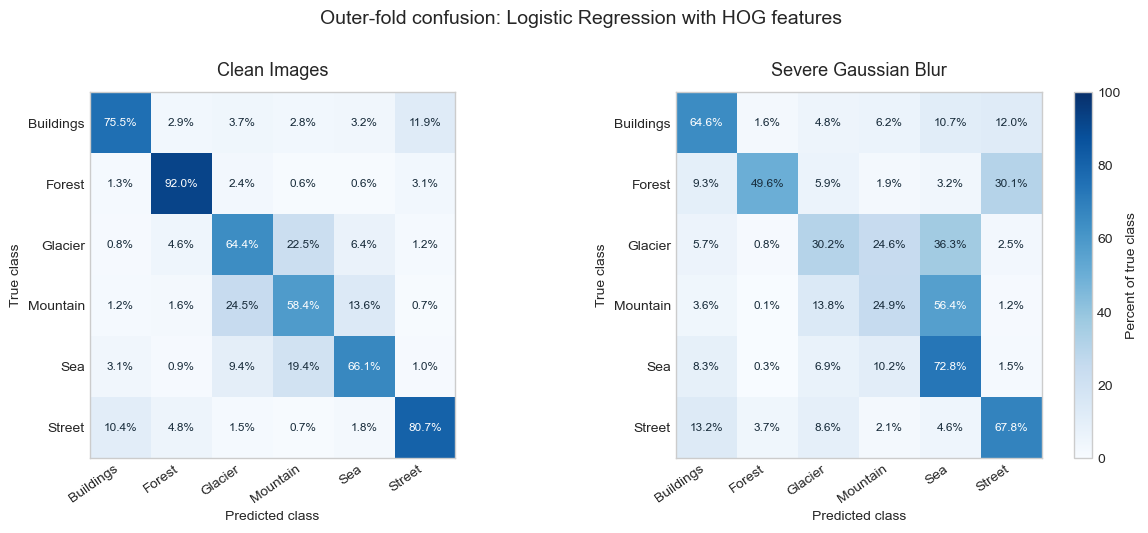

In [6]:
CLASS_NAMES = ["Buildings", "Forest", "Glacier", "Mountain", "Sea", "Street"]
clean_counts = (
    pd.read_csv(OUTPUT_DIR / "10_confusion_clean_counts.csv", index_col=0)
    .loc[CLASS_NAMES, CLASS_NAMES]
    .to_numpy(dtype=np.int64)
)
blur_counts = (
    pd.read_csv(OUTPUT_DIR / "10_confusion_severe_blur_counts.csv", index_col=0)
    .loc[CLASS_NAMES, CLASS_NAMES]
    .to_numpy(dtype=np.int64)
)
clean_percent = 100 * clean_counts / clean_counts.sum(axis=1, keepdims=True)
blur_percent = 100 * blur_counts / blur_counts.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(13.4, 5.9))
for axis, matrix, title in zip(
    axes, [clean_percent, blur_percent], ["Clean Images", "Severe Gaussian Blur"]
):
    image = axis.imshow(matrix, cmap="Blues", vmin=0, vmax=100, interpolation="nearest")
    axis.set_title(title, fontsize=13, pad=12)
    axis.set_xticks(range(6), CLASS_NAMES, rotation=35, ha="right")
    axis.set_yticks(range(6), CLASS_NAMES)
    axis.set_xlabel("Predicted class")
    axis.set_ylabel("True class")
    axis.tick_params(length=0)
    axis.grid(False)
    for row in range(6):
        for column in range(6):
            value = matrix[row, column]
            axis.text(
                column, row, f"{value:.1f}%", ha="center", va="center",
                fontsize=8.5, color="white" if value >= 50 else "#172b3a",
            )

fig.suptitle("Outer-fold confusion: Logistic Regression with HOG features", fontsize=14)
fig.subplots_adjust(left=0.08, right=0.89, bottom=0.22, top=0.84, wspace=0.34)
colorbar = fig.colorbar(image, ax=axes.ravel().tolist(), fraction=0.027, pad=0.03)
colorbar.set_label("Percent of true class")
fig.savefig(FIGURE_DIR / "10_clean_vs_severe_blur_confusion.png", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "10_clean_vs_severe_blur_confusion.pdf", bbox_inches="tight")
display(fig)
plt.close(fig)


In [7]:
def top_confusions(matrix, count=3):
    values = [
        (matrix[row, column], CLASS_NAMES[row], CLASS_NAMES[column])
        for row in range(6) for column in range(6) if row != column
    ]
    return sorted(values, reverse=True)[:count]

increases = sorted([
    (
        blur_percent[row, column] - clean_percent[row, column],
        CLASS_NAMES[row], CLASS_NAMES[column],
        clean_percent[row, column], blur_percent[row, column],
    )
    for row in range(6) for column in range(6)
    if row != column and blur_percent[row, column] > clean_percent[row, column]
], reverse=True)

clean_text = "; ".join(
    f"{true} to {predicted}: {value:.1f}%"
    for value, true, predicted in top_confusions(clean_percent)
)
increase_text = "; ".join(
    f"{true} to {predicted}: {before:.1f}% to {after:.1f}% (+{change:.1f} pp)"
    for change, true, predicted, before, after in increases[:3]
)
display(Markdown(
    f"On clean images, the largest off-diagonal confusions are {clean_text}. "
    f"Under severe Gaussian blur, the largest increases are {increase_text}."
))


On clean images, the largest off-diagonal confusions are Mountain to Glacier: 24.5%; Glacier to Mountain: 22.5%; Sea to Mountain: 19.4%. Under severe Gaussian blur, the largest increases are Mountain to Sea: 13.6% to 56.4% (+42.8 pp); Glacier to Sea: 6.4% to 36.3% (+29.8 pp); Forest to Street: 3.1% to 30.1% (+27.1 pp).